## Explore the data

In [1]:
from pathlib import Path
import pandas as pd

data_dir = Path('datasets/predicting_credit_card_fraud')

train_df = pd.read_csv(data_dir/'train.csv')
test = pd.read_csv(data_dir/'test.csv')
sample_submission = pd.read_csv(data_dir/'sample_submission.csv')

In [3]:
train_df.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [5]:
train_df.shape

(699960, 26)

In [6]:
train_df.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt', 'is_fraud'],
      dtype='str')

In [8]:
train_df.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191549,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


In [9]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


## Data Preprocessing

### Split the data

In [2]:
X = train_df.drop(columns=['id', 'is_fraud'])
y = train_df['is_fraud']

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) 

In [13]:
X_train.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,...,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
655645,110.17,12.92,2,5.66,49,28,5087.68,0,0.0,18,...,Visa,OTP,Online,Smart Watch,False,False,False,False,False,False
245864,548.02,0.79,4,16.62,51,66,1881.21,0,28.6,11,...,Visa,No Authentication,In-App,Android Phone,False,False,False,False,False,False
199967,13.47,2.38,1,11.90,40,42,1406.36,0,11.9,8,...,Discover,3D Secure,Online,iPhone,True,False,False,True,False,False
92030,33.56,3.72,2,6.54,43,80,2197.43,0,8.8,17,...,Visa,3D Secure,Online,Smart Watch,False,False,False,False,False,False
398919,34.22,5.49,5,30.91,37,47,2999.33,1,23.1,15,...,RuPay,3D Secure,Online,Android Phone,True,True,False,False,False,False


In [4]:
cat_cols = X_train.select_dtypes(include='str').columns.tolist()
cat_cols

['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']

In [5]:
bool_cols = X.select_dtypes(include="bool").columns
bool_cols

Index(['is_foreign_transaction', 'is_new_merchant', 'used_vpn',
       'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt'],
      dtype='str')

## Data Processing

In [6]:
X_train[bool_cols] = X_train[bool_cols].astype(int)

In [7]:
X_test[bool_cols] = X_test[bool_cols].astype(int)

## Model Training

In [27]:
import numpy as np
import plotly.graph_objects as go

from sklearn.metrics import roc_auc_score


def test_params(ModelClass, param_name, param_values, param_model, reference_scores=None, **other_params):
    reference_scores = reference_scores or {}

    results = {
        "param_values": [],
        "train_scores": [],
        "val_scores": [],
    }

    for value in param_values:
        params = dict(other_params)
        params[param_name] = value
        
        model = ModelClass(**params)

        model.fit(X_train, y_train, **param_model)

        # Training ROC-AUC
        train_proba = model.predict_proba(X_train)[:, 1]
        train_auc = roc_auc_score(y_train, train_proba)

        # Validation ROC-AUC
        val_proba = model.predict_proba(X_test)[:, 1]
        val_auc = roc_auc_score(y_test, val_proba)

        results["param_values"].append(value)
        results["train_scores"].append(train_auc)
        results["val_scores"].append(val_auc)

        print(f"\n{param_name} = {value}")
        print(f"Train ROC-AUC: {train_auc:.6f}")
        print(f"Validation ROC-AUC: {val_auc:.6f}")

    # Best parameter
    best_idx = np.argmax(results["val_scores"])

    best_value = param_values[best_idx]
    best_score = results["val_scores"][best_idx]

    print("\n" + "=" * 40)
    print(f"Best {param_name}: {best_value}")
    print(f"Best Validation ROC-AUC: {best_score:.6f}")
    print("=" * 40)

    # Interactive Plotly graph
    fig = go.Figure()

    # Training scores
    fig.add_trace(
        go.Scatter(
            x=param_values,
            y=results["train_scores"],
            mode="lines+markers",
            name="Training ROC-AUC",
            line=dict(width=3),
            hovertemplate=(
                f"{param_name}: %{{x}}<br>"
                "Training ROC-AUC: %{y:.6f}<extra></extra>"
            )
        )
    )

    # Validation scores
    fig.add_trace(
        go.Scatter(
            x=param_values,
            y=results["val_scores"],
            mode="lines+markers",
            name="Validation ROC-AUC",
            line=dict(width=3),
            hovertemplate=(
                f"{param_name}: %{{x}}<br>"
                "Validation ROC-AUC: %{y:.6f}<extra></extra>"
            )
        )
    )

    # Reference scores
    for label, score in reference_scores.items():

        fig.add_hline(
            y=score,
            line_dash="dash",
            annotation_text=f"{label}: {score:.5f}",
            annotation_position="top right"
        )

    # Best parameter marker
    fig.add_trace(
        go.Scatter(
            x=[best_value],
            y=[best_score],
            mode="markers",
            marker=dict(size=16, symbol="star"),
            name="Best Parameter",
        )
    )

    fig.update_layout(
        title=f"Hyperparameter Tuning: {param_name}",
        xaxis_title=param_name,
        yaxis_title="ROC-AUC",
        template="plotly_dark",
        hovermode="x unified",
        height=700,
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="left",
            x=0
        ),
    )

    fig.show()

    return results

### CatBoost

In [41]:
from catboost import CatBoostClassifier

name = CatBoostClassifier

params = {
    "task_type": "GPU",
    "thread_count": 1,
    "random_seed": 42,
    "auto_class_weights": "Balanced",
    "verbose": False,
    "allow_writing_files": False,
    "eval_metric": "AUC",
    "early_stopping_rounds": 100,
}

param_model = { 
    "cat_features": cat_cols,
    "metric_period": 1
}

In [42]:
%%time

eval_model(name, params, param_model)

Fold 1 ROC-AUC: 0.9436
Fold 2 ROC-AUC: 0.9488
Fold 3 ROC-AUC: 0.9473
Fold 4 ROC-AUC: 0.9367
Fold 5 ROC-AUC: 0.9467

Mean ROC-AUC: 0.944599
Std: 0.004294
CPU times: user 2min 33s, sys: 9.86 s, total: 2min 43s
Wall time: 2min 11s


In [43]:
model_cat_1 = name(**params)

In [44]:
%%time
model_cat_1.fit(X_train, y_train, **param_model)

CPU times: user 36.1 s, sys: 2.01 s, total: 38.1 s
Wall time: 32.4 s


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', cat_features=['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type'], early_stopping_rounds=100, eval_metric='AUC', metric_period=1, random_seed=42, task_type='GPU', thread_count=1, verbose=False)

In [45]:
from sklearn.metrics import roc_auc_score, average_precision_score

y_proba = model_cat_1.predict_proba(X_test)[:, 1]
sco_mod = model_cat_1.score(X_test, y_test)
roc_auc = roc_auc_score(y_test, y_proba)

print('Score:', sco_mod)
print('ROC-AUC:', roc_auc)

Score: 0.8913295045431168
ROC-AUC: 0.9429529074415425


In [74]:
model_cat_1.get_all_params()

{'nan_mode': 'Min',
 'gpu_ram_part': 0.95,
 'eval_metric': 'AUC',
 'combinations_ctr': ['Borders:CtrBorderCount=15:CtrBorderType=Uniform:TargetBorderCount=1:TargetBorderType=MinEntropy:Prior=0/1:Prior=0.5/1:Prior=1/1',
  'FeatureFreq:CtrBorderCount=15:CtrBorderType=Median:Prior=0/1'],
 'iterations': 1000,
 'fold_permutation_block': 64,
 'leaf_estimation_method': 'Newton',
 'observations_to_bootstrap': 'TestOnly',
 'od_pval': 0,
 'random_score_type': 'NormalWithModelSizeDecrease',
 'counter_calc_method': 'SkipTest',
 'grow_policy': 'SymmetricTree',
 'penalties_coefficient': 1,
 'boosting_type': 'Plain',
 'ctr_history_unit': 'Sample',
 'feature_border_type': 'GreedyLogSum',
 'bayesian_matrix_reg': 0.10000000149011612,
 'one_hot_max_size': 2,
 'devices': '-1',
 'eval_fraction': 0,
 'pinned_memory_bytes': '104857600',
 'force_unit_auto_pair_weights': False,
 'l2_leaf_reg': 3,
 'random_strength': 1,
 'od_type': 'Iter',
 'rsm': 1,
 'boost_from_average': False,
 'gpu_cat_features_storage': 'G

### Hyper Parameter Tuning CatBoost

In [10]:
from catboost import CatBoostClassifier

name = CatBoostClassifier

params = {
    "task_type": "GPU",
    "thread_count": 1,
    "random_seed": 42,
    "auto_class_weights": "Balanced",
    "verbose": False,
    "allow_writing_files": False,    
    "eval_metric": "AUC",
    "early_stopping_rounds": 100,
}

param_model = { 
    "cat_features": cat_cols,
    "metric_period": 1
}

reference_scores = {
    "Baseline CatBoost": 0.942952,
}


depth = 2
Train ROC-AUC: 0.946219
Validation ROC-AUC: 0.942670

depth = 3
Train ROC-AUC: 0.948038
Validation ROC-AUC: 0.943174

depth = 4
Train ROC-AUC: 0.950381
Validation ROC-AUC: 0.943512

depth = 5
Train ROC-AUC: 0.953608
Validation ROC-AUC: 0.943247

depth = 6
Train ROC-AUC: 0.958649
Validation ROC-AUC: 0.942953

depth = 7
Train ROC-AUC: 0.965918
Validation ROC-AUC: 0.941666

Best depth: 4
Best Validation ROC-AUC: 0.943512


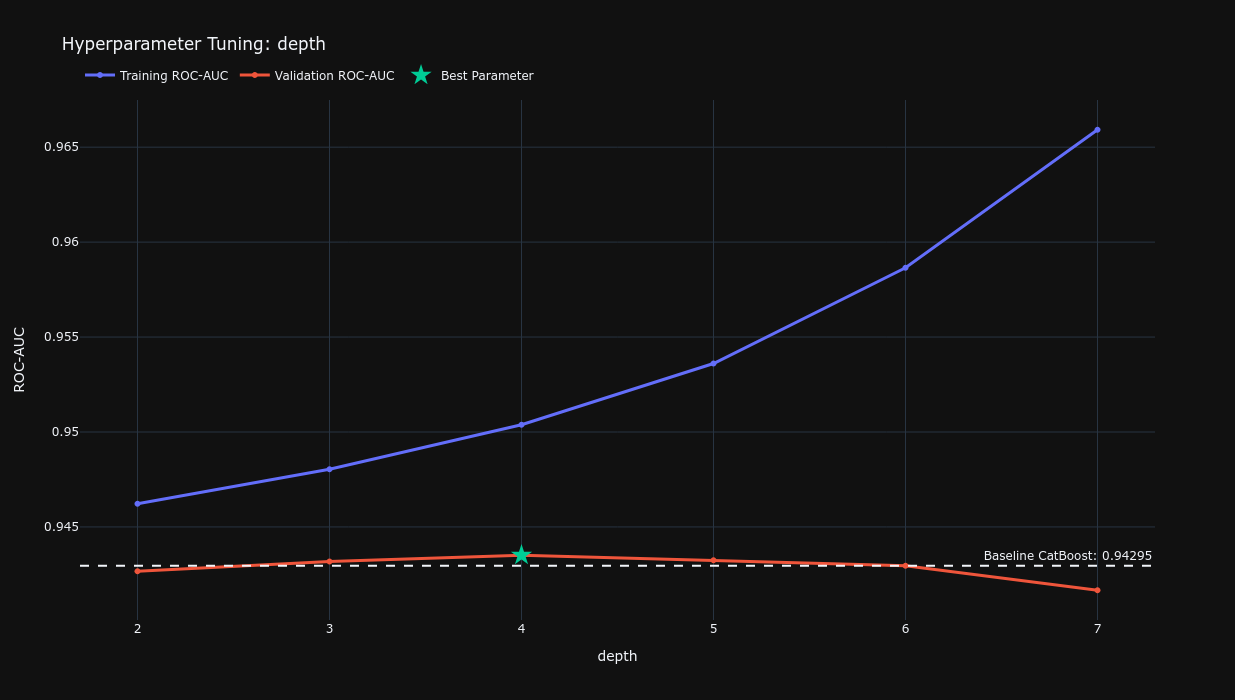

CPU times: user 2min 58s, sys: 10 s, total: 3min 8s
Wall time: 2min 31s


In [59]:
%%time

values = [2, 3, 4, 5, 6, 7]

results = test_params(
    ModelClass=CatBoostClassifier,
    param_name="depth",
    param_values=values,
    param_model=param_model,
    reference_scores=reference_scores,
    **params,
)

In [11]:
params["depth"] = 4
reference_scores["depth"] = 0.943512


iterations = 750
Train ROC-AUC: 0.950159
Validation ROC-AUC: 0.943242

iterations = 1000
Train ROC-AUC: 0.950381
Validation ROC-AUC: 0.943512

iterations = 1500
Train ROC-AUC: 0.950542
Validation ROC-AUC: 0.943387

Best iterations: 1000
Best Validation ROC-AUC: 0.943512


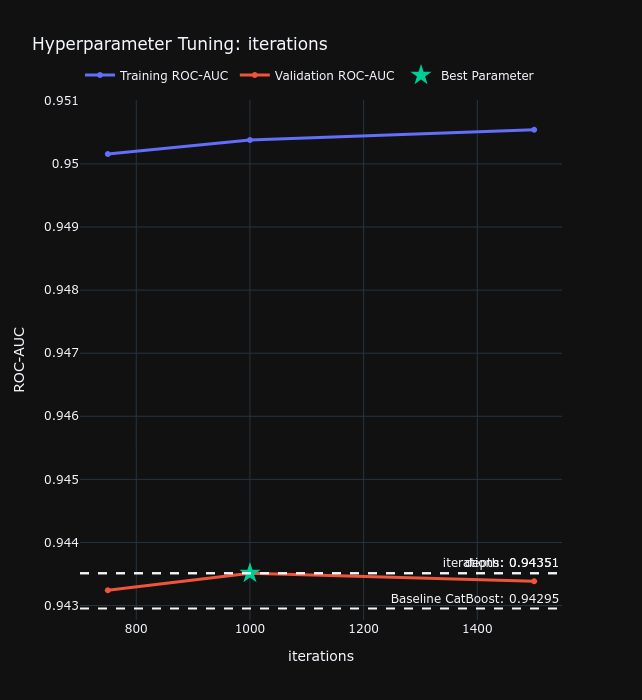

CPU times: user 1min 24s, sys: 5.05 s, total: 1min 29s
Wall time: 1min 10s


In [70]:
%%time

values = [750, 1000, 1500]

results = test_params(
    ModelClass=CatBoostClassifier,
    param_name="iterations",
    param_values=values,
    param_model=param_model,
    reference_scores=reference_scores,
    **params,
)

In [12]:
params["iterations"] = 1000
reference_scores["iterations"] = 0.943512


learning_rate = 0.01
Train ROC-AUC: 0.946567
Validation ROC-AUC: 0.942382

learning_rate = 0.03
Train ROC-AUC: 0.951677
Validation ROC-AUC: 0.943437

learning_rate = 0.05
Train ROC-AUC: 0.954990
Validation ROC-AUC: 0.943604

learning_rate = 0.1
Train ROC-AUC: 0.961443
Validation ROC-AUC: 0.943091

Best learning_rate: 0.05
Best Validation ROC-AUC: 0.943604


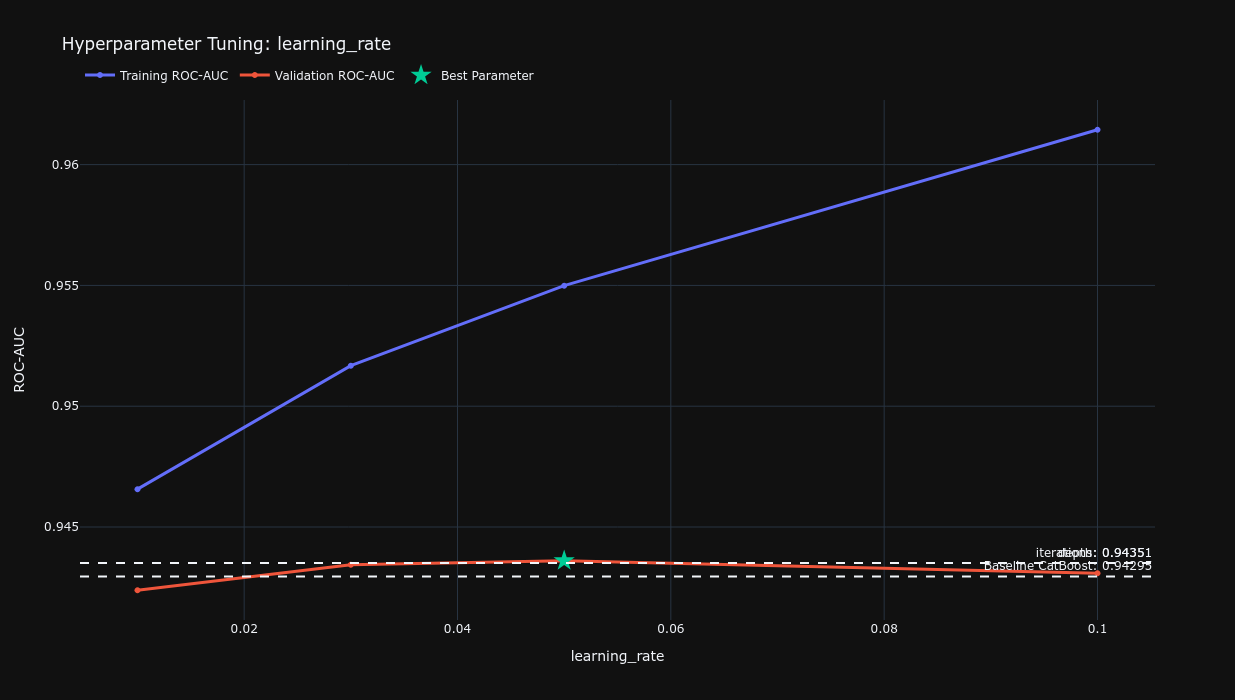

CPU times: user 1min 44s, sys: 6.31 s, total: 1min 51s
Wall time: 1min 27s


In [71]:
%%time

values = [0.01, 0.03, 0.05, 0.1]

results = test_params(
    ModelClass=CatBoostClassifier,
    param_name="learning_rate",
    param_values=values,
    param_model=param_model,
    reference_scores=reference_scores,
    **params,
)


random_strength = 0
Train ROC-AUC: 0.950326
Validation ROC-AUC: 0.943501

random_strength = 0.5
Train ROC-AUC: 0.950340
Validation ROC-AUC: 0.943476

random_strength = 1
Train ROC-AUC: 0.950381
Validation ROC-AUC: 0.943512

random_strength = 2
Train ROC-AUC: 0.950313
Validation ROC-AUC: 0.943560

random_strength = 5
Train ROC-AUC: 0.950167
Validation ROC-AUC: 0.943533

random_strength = 10
Train ROC-AUC: 0.949882
Validation ROC-AUC: 0.943393

Best random_strength: 2
Best Validation ROC-AUC: 0.943560


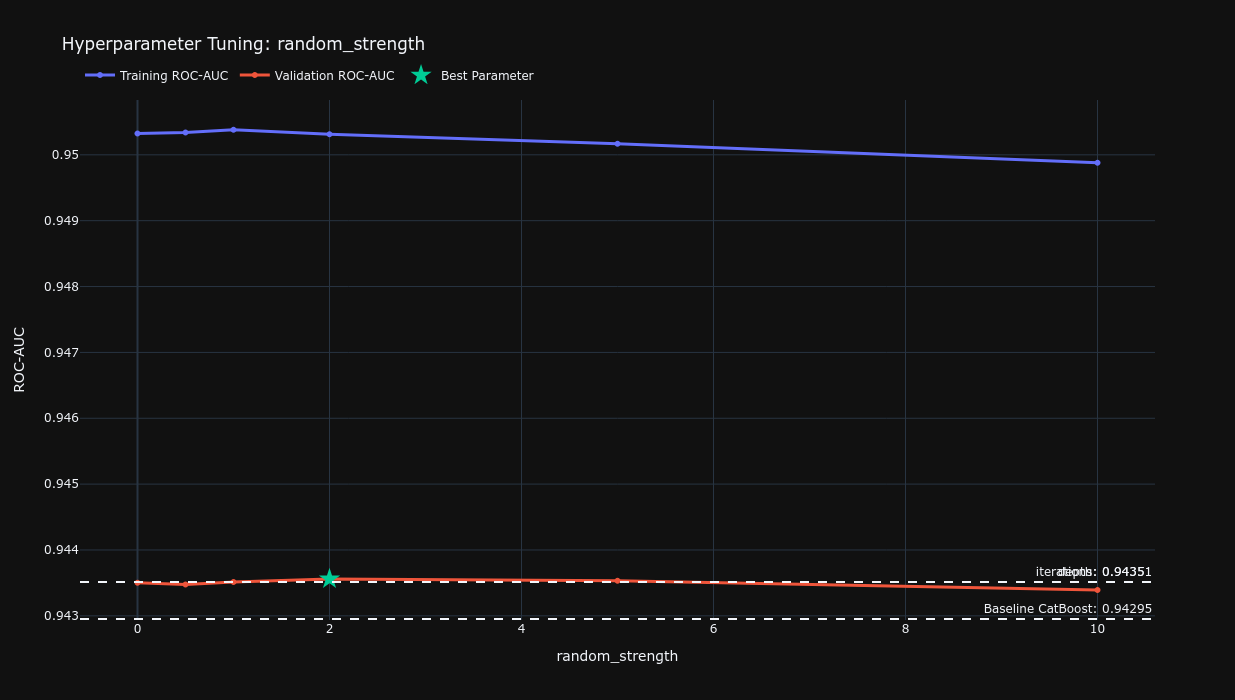

CPU times: user 2min 43s, sys: 10.7 s, total: 2min 53s
Wall time: 2min 15s


In [15]:
%%time

values = [0, 0.5, 1, 2, 5, 10]

results = test_params(
    ModelClass=CatBoostClassifier,
    param_name="random_strength",
    param_values=values,
    param_model=param_model,
    reference_scores=reference_scores,
    **params,
)

In [16]:
params["random_strength"] = 2
reference_scores["random_strength"] = 0.943560

In [17]:
params

{'task_type': 'GPU',
 'thread_count': 1,
 'random_seed': 42,
 'auto_class_weights': 'Balanced',
 'verbose': False,
 'allow_writing_files': False,
 'eval_metric': 'AUC',
 'early_stopping_rounds': 100,
 'depth': 4,
 'iterations': 1000,
 'random_strength': 2}


border_count = 128
Train ROC-AUC: 0.950318
Validation ROC-AUC: 0.943462

border_count = 254
Train ROC-AUC: 0.950463
Validation ROC-AUC: 0.943668

border_count = 512
Train ROC-AUC: 0.950774
Validation ROC-AUC: 0.943730

border_count = 1024
Train ROC-AUC: 0.950849
Validation ROC-AUC: 0.943793

Best border_count: 1024
Best Validation ROC-AUC: 0.943793


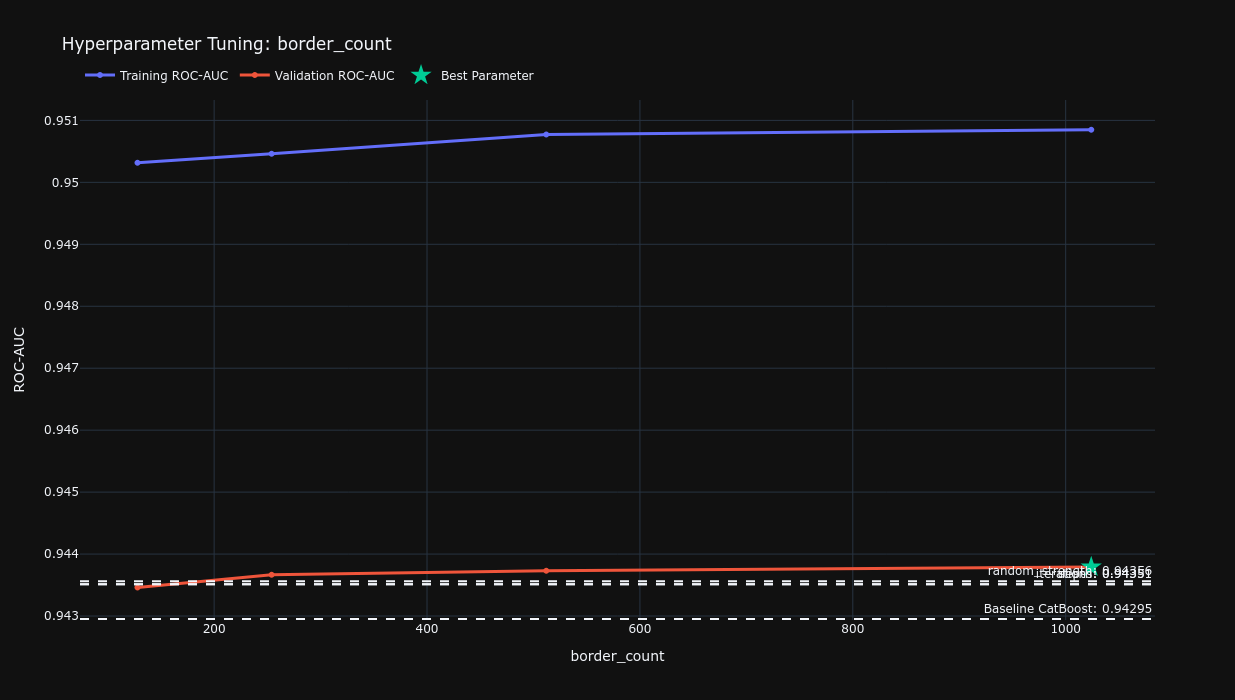

CPU times: user 1min 47s, sys: 6.88 s, total: 1min 54s
Wall time: 1min 30s


In [19]:
%%time

values = [128, 254, 512, 1024]

results = test_params(
    ModelClass=CatBoostClassifier,
    param_name="border_count",
    param_values=values,
    param_model=param_model,
    reference_scores=reference_scores,
    **params,
)

In [20]:
params["border_count"] = 512
reference_scores["border_count"] = 0.943730


bagging_temperature = 0
Train ROC-AUC: 0.952126
Validation ROC-AUC: 0.944611

bagging_temperature = 0.5
Train ROC-AUC: 0.951735
Validation ROC-AUC: 0.944159

bagging_temperature = 1
Train ROC-AUC: 0.950748
Validation ROC-AUC: 0.943696

bagging_temperature = 2
Train ROC-AUC: 0.949025
Validation ROC-AUC: 0.942729

bagging_temperature = 5
Train ROC-AUC: 0.945125
Validation ROC-AUC: 0.939415

Best bagging_temperature: 0
Best Validation ROC-AUC: 0.944611


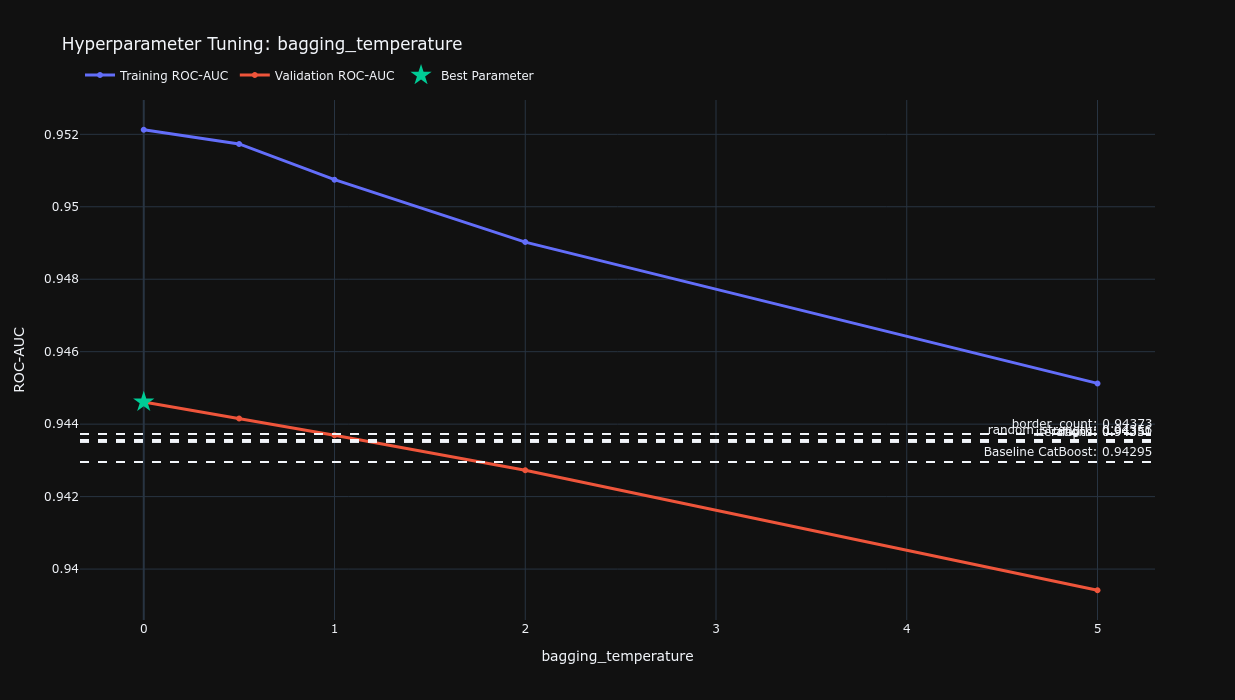

CPU times: user 2min 12s, sys: 8.1 s, total: 2min 20s
Wall time: 1min 51s


In [21]:
%%time

values = [0, 0.5, 1, 2, 5]

results = test_params(
    ModelClass=CatBoostClassifier,
    param_name="bagging_temperature",
    param_values=values,
    param_model=param_model,
    reference_scores=reference_scores,
    **params,
)

In [22]:
params["bagging_temperature"] = 0
reference_scores["bagging_temperature"] = 0.944611

In [25]:
params

{'task_type': 'GPU',
 'thread_count': 1,
 'random_seed': 42,
 'auto_class_weights': 'Balanced',
 'verbose': False,
 'allow_writing_files': False,
 'eval_metric': 'AUC',
 'early_stopping_rounds': 100,
 'depth': 4,
 'iterations': 1000,
 'random_strength': 2,
 'border_count': 512,
 'bagging_temperature': 0}

In [29]:
param_model

{'cat_features': ['merchant_category',
  'card_type',
  'auth_method',
  'channel',
  'device_type'],
 'metric_period': 1}

In [26]:
model_cat_2 = name(**params)

In [27]:
%%time
model_cat_2.fit(X_train, y_train,  **param_model)

CPU times: user 24.8 s, sys: 1.66 s, total: 26.4 s
Wall time: 22 s


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', bagging_temperature=0, border_count=512, cat_features=['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type'], depth=4, early_stopping_rounds=100, eval_metric='AUC', iterations=1000, metric_period=1, random_seed=42, random_strength=2, task_type='GPU', thread_count=1, verbose=False)

In [28]:
from sklearn.metrics import roc_auc_score, average_precision_score

y_proba = model_cat_2.predict_proba(X_test)[:, 1]
sco_mod = model_cat_2.score(X_test, y_test)
roc_auc = roc_auc_score(y_test, y_proba)

print('Score:', sco_mod)
print('ROC-AUC:', roc_auc)

Score: 0.8869006800388594
ROC-AUC: 0.9446120151014503


### LightGBM

In [8]:
for col in cat_cols:
    X_train[col] = X_train[col].astype("category")
    X_test[col] = X_test[col].astype("category")

In [21]:
from lightgbm import LGBMClassifier, early_stopping

name = LGBMClassifier

params = {
    "device": "gpu",
    "n_jobs": 1,
    "random_state": 42,
    "class_weight": "balanced",
    "verbosity": -1,
    "metric": "auc",
}

param_model = {
    "categorical_feature": cat_cols,
    "eval_X": X_test,
    "eval_y": y_test,
    "callbacks": [early_stopping(stopping_rounds=100)]
}

In [22]:
model_lgbm_1 = name(**params)

In [23]:
%%time
model_lgbm_1.fit(X_train, y_train, **param_model)

Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.942511
CPU times: user 5.34 s, sys: 175 ms, total: 5.52 s
Wall time: 5.46 s


,class_weight,'balanced'
,random_state,42
,n_jobs,1
,device,'gpu'
,verbosity,-1
,metric,'auc'
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100


In [24]:
from sklearn.metrics import roc_auc_score, average_precision_score

y_proba = model_lgbm_1.predict_proba(X_test)[:, 1]
sco_mod = model_lgbm_1.score(X_test, y_test)
roc_auc = roc_auc_score(y_test, y_proba)

print('Score:', sco_mod)
print('ROC-AUC:', roc_auc)

Score: 0.8841576661523516
ROC-AUC: 0.9425111128044561


In [25]:
params

{'device': 'gpu',
 'n_jobs': 1,
 'random_state': 42,
 'class_weight': 'balanced',
 'verbosity': -1,
 'metric': 'auc'}

### Hyper Parameter tuning Lightgbm

In [8]:
for col in cat_cols:
    X_train[col] = X_train[col].astype("category")
    X_test[col] = X_test[col].astype("category")

In [28]:
from lightgbm import LGBMClassifier, early_stopping

name = LGBMClassifier

params = {
    "device": "gpu",
    "n_jobs": 1,
    "random_state": 42,
    "class_weight": "balanced",
    "verbosity": -1,
    "metric": "auc",
}

param_model = {
    "categorical_feature": cat_cols,
    "eval_X": X_test,
    "eval_y": y_test,
    "callbacks": [early_stopping(stopping_rounds=100)]
}

reference_scores = {
    "Baseline LighGBM": 0.942511,
}

Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.942511

learning_rate = 0.1
Train ROC-AUC: 0.962167
Validation ROC-AUC: 0.942511
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[85]	valid_0's auc: 0.942552

learning_rate = 0.13
Train ROC-AUC: 0.963557
Validation ROC-AUC: 0.942552
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[85]	valid_0's auc: 0.942843

learning_rate = 0.15
Train ROC-AUC: 0.965482
Validation ROC-AUC: 0.942843
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[55]	valid_0's auc: 0.94242

learning_rate = 0.17
Train ROC-AUC: 0.960761
Validation ROC-AUC: 0.942420
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[76]	valid_0's auc: 0.942195

learn

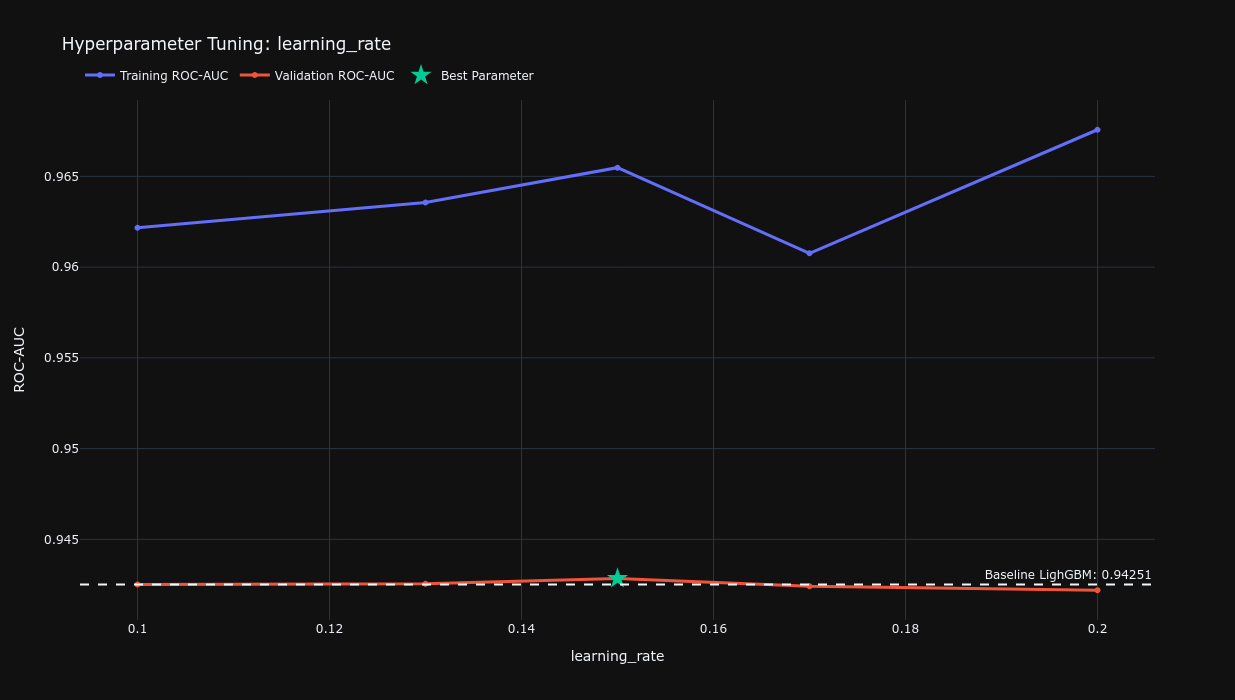

CPU times: user 35.5 s, sys: 915 ms, total: 36.4 s
Wall time: 36.3 s


In [31]:
%%time

values = [0.1, 0.13, 0.15, 0.17, 0.2]

results = test_params(
    ModelClass=name,
    param_name="learning_rate",
    param_values=values,
    param_model=param_model,
    reference_scores=reference_scores,
    **params,
)

In [36]:
params["learning_rate"] = 0.15
reference_scores["learning_rate"] = 0.942843

Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.943793

num_leaves = 7
Train ROC-AUC: 0.949354
Validation ROC-AUC: 0.943793
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[92]	valid_0's auc: 0.943328

num_leaves = 15
Train ROC-AUC: 0.956118
Validation ROC-AUC: 0.943328
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[85]	valid_0's auc: 0.942843

num_leaves = 31
Train ROC-AUC: 0.965482
Validation ROC-AUC: 0.942843
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[62]	valid_0's auc: 0.942461

num_leaves = 63
Train ROC-AUC: 0.971971
Validation ROC-AUC: 0.942461
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[48]	valid_0's auc: 0.940303

num_leaves = 127
Train R

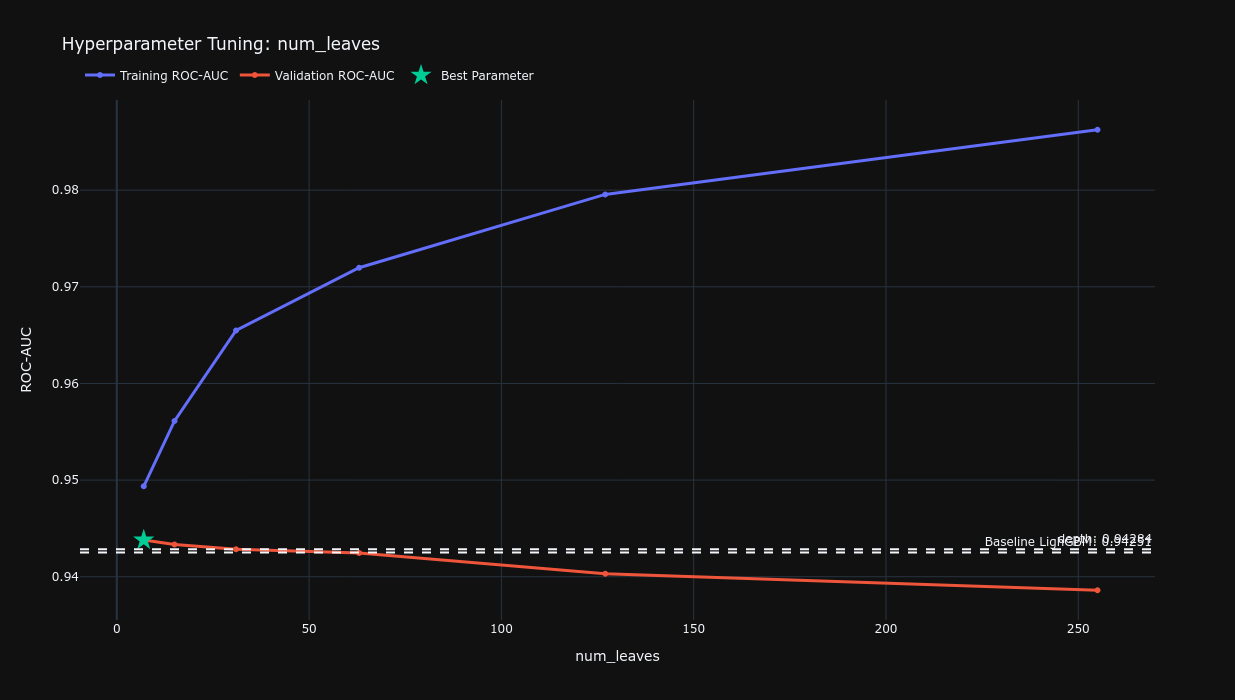

CPU times: user 43.5 s, sys: 1.13 s, total: 44.6 s
Wall time: 44.5 s


In [35]:
%%time

values = [7, 15, 31, 63, 127, 255]

results = test_params(
    ModelClass=name,
    param_name="num_leaves",
    param_values=values,
    param_model=param_model,
    reference_scores=reference_scores,
    **params,
)

In [37]:
params["num_leaves"] = 7
reference_scores["num_leaves"] = 0.943793

Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.943793

max_depth = -1
Train ROC-AUC: 0.949354
Validation ROC-AUC: 0.943793
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[99]	valid_0's auc: 0.943591

max_depth = 4
Train ROC-AUC: 0.949413
Validation ROC-AUC: 0.943591
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.943793

max_depth = 6
Train ROC-AUC: 0.949354
Validation ROC-AUC: 0.943793
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.943793

max_depth = 8
Train ROC-AUC: 0.949354
Validation ROC-AUC: 0.943793
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.943793

max_depth = 10
Train ROC-AU

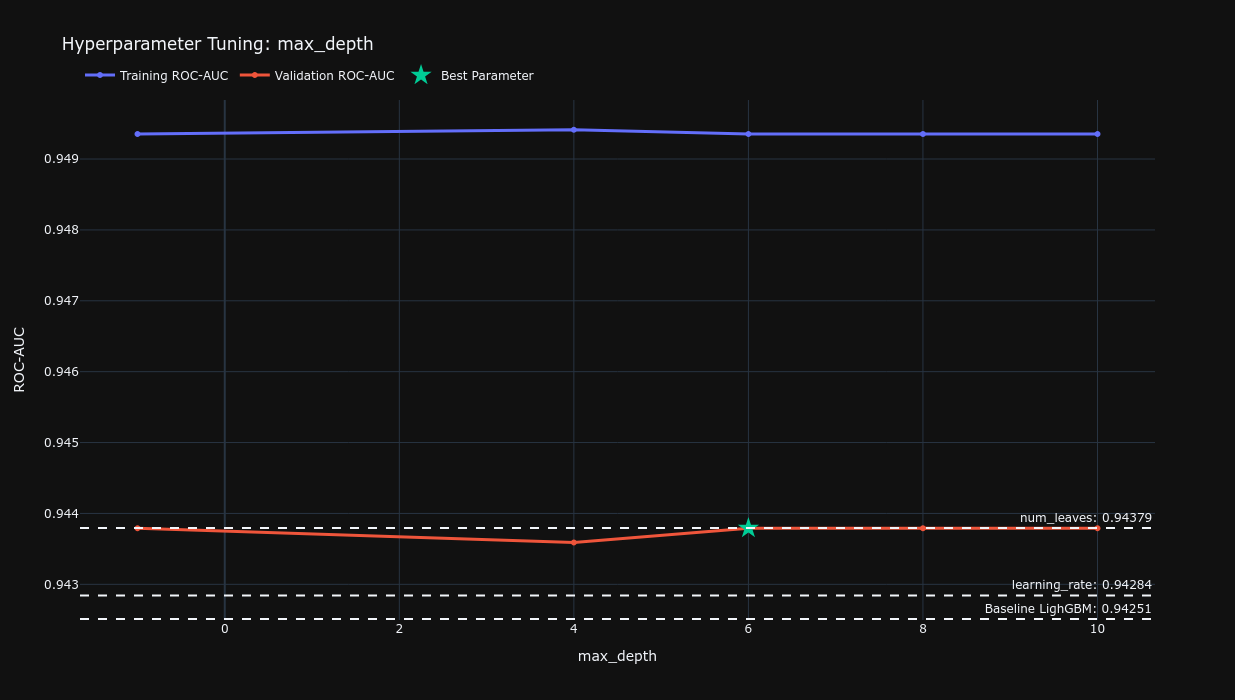

CPU times: user 27 s, sys: 863 ms, total: 27.9 s
Wall time: 27.8 s


In [40]:
%%time

values = [-1, 4, 6, 8, 10]

results = test_params(
    ModelClass=name,
    param_name="max_depth",
    param_values=values,
    param_model=param_model,
    reference_scores=reference_scores,
    **params,
)

In [41]:
params["max_depth"] = 6
reference_scores["max_depth"] = 0.943793

In [47]:
model_lgbm_2 = name(**params)

In [48]:
%%time
model_lgbm_2.fit(X_train, y_train, **param_model)

Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.943793
CPU times: user 4.08 s, sys: 163 ms, total: 4.24 s
Wall time: 4.18 s


,num_leaves,7
,max_depth,6
,learning_rate,0.15
,class_weight,'balanced'
,random_state,42
,n_jobs,1
,device,'gpu'
,verbosity,-1
,metric,'auc'
,boosting_type,'gbdt'
,n_estimators,100


In [49]:
from sklearn.metrics import roc_auc_score, average_precision_score

y_proba = model_lgbm_2.predict_proba(X_test)[:, 1]
sco_mod = model_lgbm_2.score(X_test, y_test)
roc_auc = roc_auc_score(y_test, y_proba)

print('Score:', sco_mod)
print('ROC-AUC:', roc_auc)

Score: 0.8733641922395565
ROC-AUC: 0.9437926108806818


In [50]:
params

{'device': 'gpu',
 'n_jobs': 1,
 'random_state': 42,
 'class_weight': 'balanced',
 'verbosity': -1,
 'metric': 'auc',
 'learning_rate': 0.15,
 'num_leaves': 7,
 'max_depth': 6}

## Submission

In [30]:
test_df = test.drop(columns=['id'])
test_df[bool_cols] = test_df[bool_cols].astype(int)

In [31]:
predictions = model_cat_2.predict_proba(test_df)[: ,1]
predictions

array([0.00830519, 0.0063635 , 0.83958626, ..., 0.45289311, 0.00939662,
       0.05157244], shape=(299984,))

In [32]:
ids = test["id"]
submission = pd.DataFrame({
    "id": ids,
    "is_fraud": predictions
})

In [33]:
submission.to_csv('datasets/predicting_credit_card_fraud/submissions_v2/submission_2_catboost_hypr.csv', index=False)

## Saving and getting the model

In [36]:
import joblib
from pathlib import Path

model_dir = Path('./models')
model_dir.mkdir(parents=True, exist_ok=True)

feature_cols = X_train.columns.tolist()

artifacts = {
    'model_cat_2': model_cat_2,

    'cat_cols': cat_cols,
    'bool_cols': bool_cols,
    
    'X_test': X_test,
    'y_test': y_test,
    'X_train': X_train,
    'y_train': y_train,
    'test': test,
}

artifact_path = model_dir / 'predicting_credit_card_fraud.joblib'

joblib.dump(artifacts, artifact_path)

print(f"Artifacts saved to: {artifact_path}")


Artifacts saved to: models/predicting_credit_card_fraud.joblib


In [1]:
import joblib

artifacts = joblib.load('./models/predicting_credit_card_fraud.joblib')

model_cat_2 = artifacts['model_cat_2'] 
model_lgbm_2 = artifacts['model_lgbm_2'] 
cat_cols = artifacts['cat_cols'] 
bool_cols = artifacts['bool_cols'] 
X_test = artifacts['X_test'] 
y_test = artifacts['y_test'] 
X_train = artifacts['X_train'] 
y_train = artifacts['y_train'] 
test = artifacts['test'] 

In [51]:
artifacts['model_lgbm_2'] = model_lgbm_2

In [52]:
joblib.dump(artifacts, './models/predicting_credit_card_fraud.joblib')

['./models/predicting_credit_card_fraud.joblib']

## Eval model

In [57]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np

def eval_model(name, params, param_model=None):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    scores = []

    for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):

        X_fit = X_train.iloc[train_idx]
        X_val = X_train.iloc[val_idx]

        y_fit = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        model = name(**params)

        model.fit(X_fit, y_fit, **param_model)

        y_pred_proba = model.predict_proba(X_val)[:, 1]

        score = roc_auc_score(y_val, y_pred_proba)
        scores.append(score)

        print(f"Fold {fold} ROC-AUC: {score:.4f}")

    print(f"\nMean ROC-AUC: {np.mean(scores):.6f}")
    print(f"Std: {np.std(scores):.6f}")